# 14 · The learned ranker (work package 6)

**Work package 6** of the [implementation plan](../../research/implementation_plan.md): the second stage of the
method (project plan, section 6.4).

1. **Candidates.** For each evaluated account, the best tokens by popularity and the best by the time-weighted
   neighbour score of notebook 12 (its own past tokens excluded).
2. **Features** of every (account, candidate) pair, in four groups, all computed from data before $t$:

   | Group | Features | Core problem |
   | --- | --- | --- |
   | popularity | accounts in the last 14 days and the last day; with half-lives of 1 and 7 days; popularity rank | 2 |
   | neighbours | neighbour score, plain and time-weighted; largest single similarity; number of the account's tokens pointing to the candidate | 1, 2 |
   | account | tokens in the last 14 days and in the whole past; days since the last trade; share of buys | 1 |
   | token | age; first seen in the first day of the data (age unknown); accounts in its first hour and first day; base currency of its launch pool | 3 |

3. **Label:** 1 if the account trades the candidate for the first time in the two days after $t$.
4. **Models,** simplest first: logistic regression; boosted trees with a logistic loss; boosted trees with a
   LambdaMART loss, which optimizes the order of each account's list (Burges 2010).

**Procedure.** Training rows come from the 10 Dev A points. Settings are chosen by cross-validation that holds out
whole points (5 folds of 2 consecutive points). The three rankers and the best fixed combination are compared on
the 11 Dev B points; the ablation by feature group is also run on Dev B.

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd

import plots
import protocol as pc
import ranker as rk
import stats
import token_data as td
import tuning

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = pc.RESULTS_DIR / "wp6"
OUT.mkdir(parents=True, exist_ok=True)
CONFIGS = pc.RESULTS_DIR.parent / "configs"
MODELS = td.PROJECT_DIR / "models"

legs = td.load_legs()
tokens = td.load_tokens()
wp4 = json.loads((CONFIGS / "wp4_time.json").read_text())
first_stage = {k: wp4[k] for k in ("k", "shrink", "weight", "half_life", "history_days")}
print("First stage (notebook 12):", first_stage)

First stage (notebook 12): {'k': 400, 'shrink': 200.0, 'weight': 0.2, 'half_life': 7.0, 'history_days': None}


## 1. How many candidates? Candidate recall on Dev A

Candidate recall is the share of all positive pairs (cold ones included) that are among an account's candidates:
the ceiling of anything the ranker can reach. The plan takes 500 candidates per source instead of 200 only if that
adds more than 0.02.

In [2]:
rows = []
for t in pc.POINTS["dev_a"]:
    task = pc.load_task(legs, t)
    for n in (200, 500):
        stage = rk.FirstStage(task, {**first_stage, "candidates": n})
        pairs = rk.candidates(stage, task.eval_rows)
        rows.append({"point": t, "per_source": n, "candidate_recall": rk.candidate_recall(task, pairs),
                     "candidates_per_account": len(pairs) / len(task.eval_rows)})  # fmt: skip
candidate_table = pd.DataFrame(rows)
candidate_table.to_csv(OUT / "candidate_recall_dev_a.csv", index=False)
mean_recall = candidate_table.groupby("per_source")[["candidate_recall", "candidates_per_account"]].mean()
mean_recall

,candidate_recall,candidates_per_account
per_source,,
200,0.4197,306.1612
500,0.5398,682.1473


In [3]:
gain = mean_recall.loc[500, "candidate_recall"] - mean_recall.loc[200, "candidate_recall"]
N = 500 if gain > 0.02 else 200
settings = {**first_stage, "candidates": N}
print(f"500 instead of 200 adds {gain:+.4f} to candidate recall -> {N} candidates per source")

500 instead of 200 adds +0.1202 to candidate recall -> 500 candidates per source


## 2. The rows of Dev A and Dev B

One row per (point, account, candidate). Building them takes a while, so they are cached in `data/project/ranker/`
and read one point at a time: all rows of 21 points would not fit in memory together.

- **Training rows:** every positive row, with at most 50 random negative rows of each account at each Dev A point
  (seed 0).
- **Validation rows:** every candidate of 2,000 random accounts of each Dev A point (seed 0); the recall of a random
  sample of accounts estimates the recall of all of them.
- **Dev B** is always scored on every candidate of every account.

In [4]:
tasks = {t: pc.load_task(legs, t) for t in pc.POINTS["dev_a"] + pc.POINTS["dev_b"]}
train_parts, valid_parts = [], []
for t in pc.POINTS["dev_a"] + pc.POINTS["dev_b"]:
    point = rk.point_rows(legs, tokens, tasks[t], settings)  # builds and caches the rows of Dev B points too
    if t in pc.POINTS["dev_a"]:
        train_parts.append(rk.sample_negatives(point, per_user=50, seed=0))
        valid_parts.append(rk.sample_users(point, per_point=2000, seed=0))
    print(f"  {t:%d %b}: {len(point):,} rows, {point['label'].sum():,} positive", flush=True)
    del point

train_sorted = pd.concat(train_parts, ignore_index=True).sort_values(["point", "user"], kind="stable").reset_index(drop=True)
valid_rows = pd.concat(valid_parts, ignore_index=True)
positives_a = rk.positives_per_user({t: tasks[t] for t in pc.POINTS["dev_a"]})
print(f"training rows: {len(train_sorted):,} ({train_sorted['label'].mean():.2%} positive); "
      f"validation rows: {len(valid_rows):,}")  # fmt: skip

  02 Jul: 6,744,219 rows, 12,527 positive


  04 Jul: 8,377,363 rows, 12,858 positive


  06 Jul: 9,692,568 rows, 14,172 positive


  08 Jul: 4,614,959 rows, 10,966 positive


  10 Jul: 3,857,317 rows, 8,476 positive


  12 Jul: 3,450,855 rows, 7,814 positive


... (12 outputs left out)

  07 Aug: 3,670,577 rows, 6,633 positive


  09 Aug: 3,735,727 rows, 6,542 positive


  11 Aug: 3,918,399 rows, 7,279 positive


training rows: 3,770,270 (2.55% positive); validation rows: 13,634,454


## 3. Settings by cross-validation over held-out points

For each model kind and setting: train on 8 Dev A points, score the 2 held out, five times; the score is the mean
recall@10 of the held-out points. The number of trees is a setting of the grid (100 or 300) rather than found by
early stopping, which keeps the procedure the same for every model.

In [5]:
GRIDS = {
    "logistic": [{"C": c} for c in (0.01, 0.1, 1, 10)],
    "gbdt": tuning.grid_settings(num_leaves=[15, 31], learning_rate=[0.05], min_data_in_leaf=[100, 1000], n_trees=[100, 300]),
    "lambdamart": tuning.grid_settings(num_leaves=[15, 31], learning_rate=[0.05], min_data_in_leaf=[100, 1000], n_trees=[100, 300]),
}
CV_FILE = OUT / "cv_dev_a.csv"

# Each setting's score is appended to CV_FILE as soon as it is known, so a stopped run resumes.
cv = pd.read_csv(CV_FILE) if CV_FILE.exists() else pd.DataFrame(columns=["kind", "params", "cv_recall"])
for kind, grid in GRIDS.items():
    for params in grid:
        if ((cv["kind"] == kind) & (cv["params"] == json.dumps(params))).any():
            continue
        trees = params.get("n_trees")
        score = rk.cv_over_points(kind, params, valid_rows, train_sorted, positives_a, rk.ALL_FEATURES, trees)
        cv = pd.concat([cv, pd.DataFrame([{"kind": kind, "params": json.dumps(params), "cv_recall": score}])], ignore_index=True)
        cv.to_csv(CV_FILE, index=False)
        print(f"  {kind:<11} {params}: {score:.4f}", flush=True)
cv["cv_recall"] = cv["cv_recall"].astype(float)

best = cv.loc[cv.groupby("kind")["cv_recall"].idxmax()].set_index("kind")
best

,params,cv_recall
kind,,
gbdt,"{""num_leaves"": 31, ""learning_rate"": 0.05, ""min...",0.2065
lambdamart,"{""num_leaves"": 31, ""learning_rate"": 0.05, ""min...",0.2242
logistic,"{""C"": 0.01}",0.1830


## 4. Dev B: the three rankers against the baseline and the best fixed combination

Each ranker is refitted on all 10 Dev A points with its chosen setting and then scores every Dev B point.

In [6]:
fitted = {}
for kind, row in best.iterrows():
    params = json.loads(row["params"])
    fitted[kind] = rk.fit_model(kind, train_sorted, rk.ALL_FEATURES, params, params.get("n_trees"))
    rk.save_model(fitted[kind], MODELS / f"{kind}.model")
    print(f"  fitted {kind}: {params}", flush=True)


def run_once(name: str, factory, path) -> pd.DataFrame:
    """protocol.run on Dev B, or its saved per-point table if this run was already done (so a stopped run resumes)."""
    if path.exists():
        return pd.read_csv(path, parse_dates=["point"])
    table = pc.run(name, factory, legs, pc.POINTS["dev_b"], verbose=False).per_point
    table.to_csv(path, index=False)
    print(f"  {name}: recall {table['recall'].mean():.4f}", flush=True)
    return table


def ranker_factory(model, feature_names):
    """A protocol scorer factory that ranks each point's cached candidate rows with a fitted model."""

    def factory(task):
        return rk.ranker_scorer(model, feature_names, task, rk.point_rows(legs, tokens, task, settings))

    return factory


DEV_B = pc.POINTS["dev_b"]
baseline_b = pd.read_csv(pc.RESULTS_DIR / "wp2" / "baseline_dev.csv", parse_dates=["point"]).query("part == 'dev_b'")
timed_b = pd.read_csv(pc.RESULTS_DIR / "wp4" / "time_weighted_blend_dev_b.csv", parse_dates=["point"])
untimed_b = pd.read_csv(pc.RESULTS_DIR / "wp3" / "fixed_blend_dev_b.csv", parse_dates=["point"])
results = {"popularity (baseline)": baseline_b, "fixed blend": untimed_b, "time-weighted blend": timed_b}
for kind, model in fitted.items():
    name = f"ranker: {kind}"
    results[name] = run_once(name, ranker_factory(model, rk.ALL_FEATURES), OUT / f"ranker_{kind}_dev_b.csv")

comparison = stats.compare(results, baseline="popularity (baseline)")
comparison.to_csv(OUT / "compare_dev_b.csv", index=False)
comparison

  fitted gbdt: {'num_leaves': 31, 'learning_rate': 0.05, 'min_data_in_leaf': 100, 'n_trees': 300}


  fitted lambdamart: {'num_leaves': 31, 'learning_rate': 0.05, 'min_data_in_leaf': 1000, 'n_trees': 300}


  fitted logistic: {'C': 0.01}


,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
0,popularity (baseline),11,0.0936,0.0773,0.1053,NaN,NaN,NaN,NaN,NaN
1,fixed blend,11,0.1422,0.1219,0.1561,0.0486,0.0446,0.0523,11 of 11,0.0010
2,time-weighted blend,11,0.1426,0.1240,0.1570,0.0491,0.0441,0.0535,11 of 11,0.0010
3,ranker: gbdt,11,0.1398,0.1249,0.1523,0.0462,0.0426,0.0498,11 of 11,0.0010
4,ranker: lambdamart,11,0.1460,0.1352,0.1637,0.0524,0.0470,0.0583,11 of 11,0.0010
5,ranker: logistic,11,0.1296,0.1120,0.1425,0.0360,0.0322,0.0398,11 of 11,0.0010


Each ranker against the **best fixed combinations**, point by point: the gain from learning the combination,
separated from the gain from the signals. On Dev B the untimed blend (notebook 11) and the time-weighted blend
(notebook 12) are tied, so both are shown.

In [7]:
rows_vs_fixed = []
for name in [n for n in results if n.startswith("ranker")]:
    for reference in ["fixed blend", "time-weighted blend"]:
        d = stats.paired_differences(results[name], results[reference])
        low, high = stats.bootstrap_over_points(d)
        rows_vs_fixed.append({"model": name, "against": reference, "mean_difference": d.mean(), "interval_low": low,
                              "interval_high": high, "wins": f"{stats.sign_test(d)['wins']} of {len(d)}"})  # fmt: skip
vs_fixed = pd.DataFrame(rows_vs_fixed)
vs_fixed.to_csv(OUT / "rankers_vs_fixed_dev_b.csv", index=False)
vs_fixed

,model,against,mean_difference,interval_low,interval_high,wins
0,ranker: gbdt,fixed blend,-0.0025,-0.0060,0.0019,3 of 11
1,ranker: gbdt,time-weighted blend,-0.0029,-0.0066,0.0010,4 of 11
2,ranker: lambdamart,fixed blend,0.0038,-0.0033,0.0115,6 of 11
3,ranker: lambdamart,time-weighted blend,0.0034,-0.0038,0.0109,5 of 11
4,ranker: logistic,fixed blend,-0.0126,-0.0173,-0.0077,1 of 11
5,ranker: logistic,time-weighted blend,-0.0130,-0.0170,-0.0088,0 of 11


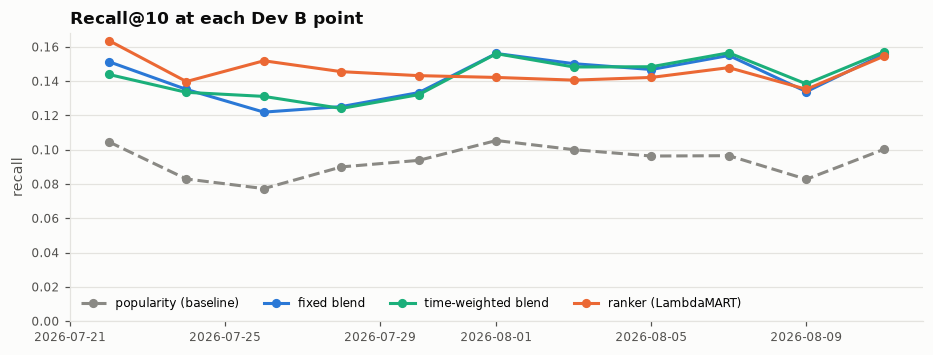

In [8]:
# The chart shows the best ranker only; the other two are in the table above (six lines would need more colours
# than can be told apart).
shown = ["popularity (baseline)", "fixed blend", "time-weighted blend"]
lines = {name: results[name] for name in shown}
lines["ranker (LambdaMART)"] = results["ranker: lambdamart"]
fig, ax = plt.subplots(figsize=(10, 3.4))
plots.per_point_lines(ax, lines)
ax.set_title("Recall@10 at each Dev B point")
plt.show()

## 5. Ablation: what does each feature group contribute?

The best ranker on Dev B is retrained on Dev A without one feature group at a time, and once with the popularity
group only, then scored on Dev B. A large drop when a group is removed means the group carries information the
others do not.

In [9]:
chosen_kind = comparison[comparison["model"].str.startswith("ranker")].sort_values("mean", ascending=False).iloc[0]["model"].split(": ")[1]
params = json.loads(best.loc[chosen_kind, "params"])
variants = {f"without {group}": [f for f in rk.ALL_FEATURES if f not in features] for group, features in rk.FEATURE_GROUPS.items()}
variants["popularity only"] = rk.FEATURE_GROUPS["popularity"]

ablation = {"all features": results[f"ranker: {chosen_kind}"]}
for name, feature_names in variants.items():
    path = OUT / f"ablation_{name.replace(' ', '_')}_dev_b.csv"
    if path.exists():
        ablation[name] = pd.read_csv(path, parse_dates=["point"])
        continue
    model = rk.fit_model(chosen_kind, train_sorted, feature_names, params, params.get("n_trees"))
    ablation[name] = run_once(name, ranker_factory(model, feature_names), path)
ablation_table = pd.DataFrame({
    name: {"recall": t["recall"].mean(), "difference_from_all": (t["recall"].to_numpy() - ablation["all features"]["recall"].to_numpy()).mean()}
    for name, t in ablation.items()
}).T  # fmt: skip
ablation_table.to_csv(OUT / "ablation_dev_b.csv")
(CONFIGS / "wp6_ranker.json").write_text(json.dumps({"kind": chosen_kind, "params": params, "first_stage": settings,
                                                      "features": rk.ALL_FEATURES}, indent=2))  # fmt: skip
ablation_table

,recall,difference_from_all
all features,0.1460,0.0000
without popularity,0.1376,-0.0085
without neighbours,0.1049,-0.0412
without user,0.1442,-0.0018
without token,0.1481,0.0020
popularity only,0.1006,-0.0454


## 6. Reading

- **The candidates set the ceiling.** With 500 candidates per source, 54% of the positive pairs on Dev A are among
  an account's candidates (42% with 200). No ranker can find the other 46%; most of them are tokens that did not
  exist at $t$ or that neither popularity nor neighbours bring up.
- **LambdaMART is the best ranker**, as in cross-validation: recall@10 0.146 on Dev B, against 0.140 for boosted
  trees with the logistic loss and 0.130 for logistic regression. All three beat the baseline at every Dev B point.
- **Against the best fixed combination the gain is small and not established.** LambdaMART minus the untimed
  blend: +0.004, 95% interval −0.003 to +0.012, 6 wins of 11; minus the time-weighted blend: +0.003, interval
  −0.004 to +0.011, 5 of 11. Boosted trees and logistic regression are below the fixed blends, logistic regression
  clearly (−0.013, 0 or 1 wins of 11). Research question 4 ("does a learned ranker beat the best fixed
  combination on periods it was not trained on?") is answered: not detectably on 11 points.
- **Ablation: the neighbour features carry the model.** Without them recall drops by 0.041, to 0.105, about the
  level of popularity alone (0.101). Without popularity features it drops by 0.009, without user features by
  0.002. **Without the token features recall rises by 0.002**: age, early accounts and launch currency do not help
  the ranker, as they did not help the cold-start lists in notebook 13.
- **Cross-validation on Dev A was optimistic.** Held-out Dev A recall was 0.224 for LambdaMART against 0.146 on
  Dev B, a larger fall than the fixed blends show (0.202 → 0.142). Part of it is that Dev A has more coordinated
  groups (notebook 11, section 2b), which the ranker can learn and which are rarer on Dev B.

- **The ranker's advantage fades with distance from its training period.** Against the untimed blend, LambdaMART
  is ahead at each of the first 5 Dev B points (22 July – 30 July; +0.016 on average) and behind at 5 of the last 6
  (1 – 11 August; −0.006 on average). The ranker is trained once on Dev A and not refitted, while the blends are
  refitted at every point from that point's history. The test period lies further from Dev A still, so this is a
  risk for choosing the ranker as the primary model.

The chosen ranker (LambdaMART, all features) is written to `configs/wp6_ranker.json`. Which model is the primary
one for the test is decided on Dev B before the freeze (implementation plan, 9.1).